# StreamLoop: tuning the churn model

**Context.** StreamLoop's first churn classifier was trained once with default settings and checked on accuracy. The tech lead wants proof that its configuration was *searched for*, not guessed, and an explanation of *why* the final configuration was picked.

**Business priority.** A customer who churns without being noticed costs StreamLoop much more than a retention offer sent to someone who would have stayed. The model is judged on how many churners it catches, not on accuracy.

**Notebook outline.** The sections follow *What You Need to Do* in `StreamLoop_Hyperparams.md`:

1. **Baseline**: load and clean the data, split it, build the pipeline, and score a default-settings model.
2. **Searching**: pick a business-driven scoring metric, run a broad `RandomizedSearchCV`, narrow the space, and refine it with `GridSearchCV`.
3. **Selecting the final model**: read `cv_results_` for variation across folds, choose and justify the final model, and score it on the test set once.
4. **Final verdict**: the summary and recommendation.

**Rules this notebook keeps:**
- All preprocessing that learns from the data sits inside a scikit-learn `Pipeline`.
- Both searches are fit on the training split only, with cross-validation and `n_jobs=-1`.
- The test set is scored exactly twice: once for the baseline and once for the final tuned model.

Helper functions live in `streamloop_churn_tuning.py`, so this notebook and the script share one implementation. The narrative is in `tuning_report.md`.

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, roc_auc_score, roc_curve
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV

from streamloop_churn_tuning import (
    CV, F2_SCORER, N_ITER, NEAR_TIE_BAND, PARAM_DISTRIBUTIONS, RANDOM_STATE,
    build_pipeline, load_customers, split_customers, metrics_from_predictions,
    candidate_table, narrow_search_space, select_from_grid,
)
pd.set_option('display.max_colwidth', None)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

FIG_DIR = Path('artifacts/figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG_DIR / f'{name}.png', bbox_inches='tight')
    plt.show()

## 1. Baseline

The baseline answers a simple question: *how good is the model before any tuning?* Every later improvement is measured against it, so it has to be built the same way the tuned model will be, using the same split, the same pipeline and the same metrics.

### Load and minimally clean

The dataset is loaded straight from the public URL given in the challenge. Cleaning is kept to the minimum needed to make it usable:

- **Drop `customerID`.** It identifies a row and carries no predictive signal.
- **Convert `TotalCharges` to a number.** In the raw file it is text, and a few values are blank strings.
- **Fill the blank `TotalCharges` values with 0.** Every blank belongs to a customer with `tenure == 0`, a new account that has not been billed yet, so 0 is the true value rather than a guess.

None of these steps estimates anything from the data, such as a mean or a category frequency, so doing them before the split does not leak test information. Anything that *does* learn from the data, like imputation and encoding, happens inside the pipeline below.

**What to look for:** 7,043 rows, a churn rate of about 26.5%, and no `TotalCharges` values left missing.

In [2]:
df, profile = load_customers()
profile

{'source': 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv',
 'rows': 7043,
 'columns_after_id_drop': 20,
 'churn_rate': 0.2653698707936959,
 'totalcharges_filled_as_zero_for_tenure_0': 11,
 'totalcharges_still_missing': 0}

### Split before anything touches a model

The data is split into training (80%) and test (20%) sets **before** any model or transformer is fit. Stratifying on `Churn` gives both sets the same churn rate, and `random_state=42` makes the split reproducible.

From here on:
- **Training split (5,634 rows):** used for fitting, cross-validation and both hyperparameter searches.
- **Test split (1,409 rows):** set aside. It is used only to score the baseline and the final model.

**What to look for:** almost identical churn rates in the two splits (about 0.265).

In [3]:
x_train, x_test, y_train, y_test = split_customers(df)
len(x_train), len(x_test), round(y_train.mean(), 4), round(y_test.mean(), 4)

(5634, 1409, np.float64(0.2654), np.float64(0.2654))

### Class balance in the training split

Before choosing a metric, it helps to see the outcome distribution. This chart uses training labels only.

**Why it matters:** about three in four customers stay. A "model" that predicts *stays* for everyone would be about 73% accurate and would catch zero churners. Accuracy therefore rewards the wrong behaviour here, which is why the search will not optimize it.

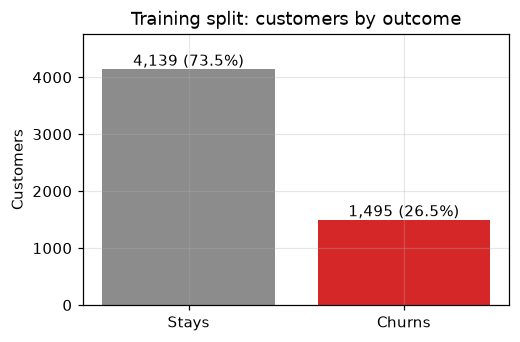

In [4]:
counts = y_train.map({0: 'Stays', 1: 'Churns'}).value_counts()[['Stays', 'Churns']]
fig, ax = plt.subplots(figsize=(5, 3.2))
bars = ax.bar(counts.index, counts.values, color=['#8c8c8c', '#d62728'])
ax.bar_label(bars, labels=[f'{v:,} ({v / counts.sum():.1%})' for v in counts.values])
ax.set_title('Training split: customers by outcome')
ax.set_ylabel('Customers')
ax.set_ylim(0, counts.max() * 1.15)
save(fig, '01_class_balance')

### Pipeline: preprocessing lives inside it

The challenge requires preprocessing to sit inside a `Pipeline` rather than being applied to the data beforehand. Wrapping every step in one estimator means that during cross-validation the imputers and encoder are **re-fit on each training fold only**, so the validation fold never influences them. The same holds for the final fit on the training split.

| Step | Columns | What it does |
| --- | --- | --- |
| Median `SimpleImputer` | `tenure`, `MonthlyCharges`, `TotalCharges`, `SeniorCitizen` | Fills any missing numeric value with the training median. |
| Most-frequent `SimpleImputer` + `OneHotEncoder` | All other columns (contract, services, payment, and so on) | Fills gaps, then turns each category into 0/1 columns. Categories not seen in training are ignored. |
| `RandomForestClassifier` | All encoded features | The classifier being tuned. `random_state=42` is fixed for reproducibility only. |

No scaler is used: tree splits do not depend on feature scale.

The challenge does not grade the choice of model family. A random forest was chosen because it has a meaningful hyperparameter surface: depth, leaf size, feature sampling and class weighting.

In [5]:
build_pipeline()

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default

### Default-hyperparameter baseline (test-set use 1 of 2)

The pipeline is trained with scikit-learn's **default** forest settings (100 trees, unlimited depth, no class weighting) and scored on the test set. This is the first of the only two times the test set is used.

Six metrics are recorded, and the same six are reported for the final model so the comparison is like for like:

- **F2**: the business metric chosen for the search (explained in the next section).
- **Recall**: the share of real churners the model catches.
- **Precision**: the share of flagged customers who really churn.
- **F1**: the balance of precision and recall with equal weight.
- **ROC AUC**: how well the model ranks churners above non-churners, independent of the cutoff.
- **Accuracy**: shown for context, not optimized.

**What to look for:** accuracy looks respectable (about 0.78), but recall is only about 0.50. The default model misses roughly half of the customers who are about to leave.

In [6]:
baseline = build_pipeline()
baseline.fit(x_train, y_train)
baseline_pred = baseline.predict(x_test)
baseline_proba = baseline.predict_proba(x_test)[:, 1]
baseline_test = metrics_from_predictions(y_test, baseline_pred, baseline_proba)
pd.Series(baseline_test, name='baseline').round(4)

f2           0.5167
recall       0.4973
precision    0.6118
f1           0.5487
roc_auc      0.8226
accuracy     0.7828
Name: baseline, dtype: float64

## 2. Searching

The search runs in two stages, as the challenge asks:

1. **Broad and cheap:** `RandomizedSearchCV` samples configurations from a wide space to find the promising region.
2. **Narrow and precise:** `GridSearchCV` tries every combination in a small grid around that region.

Both stages use the same settings so their results are comparable:
- **Cross-validation:** stratified 5-fold on the training split only (`StratifiedKFold`, `shuffle=True`, `random_state=42`).
- **`n_jobs=-1`:** all CPU cores in parallel.
- **`refit=True` (the default):** scikit-learn retrains the best configuration on the full training split automatically. It is not re-fit manually afterwards.

### Scoring metric: F2, not accuracy

The `scoring` parameter is set deliberately to **F2** (`fbeta_score` with `beta=2`) instead of the default accuracy:

- **Business reason:** a missed churner (false negative) is far more expensive than an unnecessary retention offer (false positive). F2 weights recall more heavily than precision, so the search favours configurations that catch more churners.
- **Why not recall alone:** maximizing recall would reward flagging *every* customer. F2 still penalizes poor precision, so that degenerate solution scores badly.
- **Why not accuracy:** as the class-balance chart showed, accuracy can look good while the model catches almost no churners.

The decision threshold stays at scikit-learn's default of 0.5. Tuning the threshold is a separate exercise and out of scope here.

### Broad search: `RandomizedSearchCV`

The search space below covers the forest's most influential hyperparameters, using only values `RandomForestClassifier` actually supports. Keys are prefixed `model__` because they target the `model` step inside the pipeline.

| Hyperparameter | What it controls | Values searched |
| --- | --- | --- |
| `n_estimators` | Number of trees | 100, 200, 300 |
| `max_depth` | How deep each tree may grow (overfitting control) | 4, 8, 12, 20, unlimited |
| `min_samples_split` | Minimum rows needed to split a node | 2, 5, 10, 20 |
| `min_samples_leaf` | Minimum rows in a leaf (smooths predictions) | 1, 2, 4, 8 |
| `max_features` | Features considered at each split | sqrt, log2, 50% |
| `class_weight` | Up-weights the minority (churn) class | none, balanced, balanced_subsample |

That is 2,160 combinations. The random search samples **24** of them, each evaluated with 5-fold cross-validation, for 120 fits in total. The point is to learn which *region* of the space is promising cheaply, not to find the exact optimum.

In [7]:
PARAM_DISTRIBUTIONS

{'model__n_estimators': [100, 200, 300],
 'model__max_depth': [4, 8, 12, 20, None],
 'model__min_samples_split': [2, 5, 10, 20],
 'model__min_samples_leaf': [1, 2, 4, 8],
 'model__max_features': ['sqrt', 'log2', 0.5],
 'model__class_weight': [None, 'balanced', 'balanced_subsample']}

In [8]:
random_search = RandomizedSearchCV(
    build_pipeline(), PARAM_DISTRIBUTIONS, n_iter=N_ITER, scoring=F2_SCORER,
    cv=CV, n_jobs=-1, refit=True, random_state=RANDOM_STATE,
)
random_search.fit(x_train, y_train)
pd.DataFrame(candidate_table(random_search, limit=5))[['mean_f2', 'std_f2', 'fold_range', 'params']].round(4)

,mean_f2,std_f2,fold_range,params
0,0.7205,0.0169,0.0528,"{'model__n_estimators': 300, 'model__min_samples_split': 10, 'model__min_samples_leaf': 2, 'model__max_features': 'log2', 'model__max_depth': 4, 'model__class_weight': 'balanced'}"
1,0.7191,0.0186,0.0560,"{'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_features': 'log2', 'model__max_depth': 8, 'model__class_weight': 'balanced'}"
2,0.7153,0.0158,0.0460,"{'model__n_estimators': 200, 'model__min_samples_split': 5, 'model__min_samples_leaf': 8, 'model__max_features': 'log2', 'model__max_depth': 8, 'model__class_weight': 'balanced_subsample'}"
3,0.7153,0.0172,0.0539,"{'model__n_estimators': 100, 'model__min_samples_split': 5, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': 4, 'model__class_weight': 'balanced_subsample'}"
4,0.7144,0.0207,0.0588,"{'model__n_estimators': 100, 'model__min_samples_split': 20, 'model__min_samples_leaf': 1, 'model__max_features': 'log2', 'model__max_depth': 8, 'model__class_weight': 'balanced_subsample'}"


### What the random search found

Each point is one sampled configuration: its mean cross-validated F2, with an error bar of ±1 standard deviation across the 5 folds. Colour shows `class_weight`.

**How to read it:**
- **Class weighting is the dominant factor.** Every unweighted forest (grey) sits at the bottom, roughly 0.41 to 0.53 F2. Every weighted forest scores roughly 0.64 to 0.72. Without weighting, the forest leans towards the majority "stays" class and misses churners.
- **Shallower trees with `log2` feature sampling lead.** The top configurations use depth 4 or 8. Unlimited depth and 50% feature sampling rank lower.
- **The error bars overlap among the leaders**, so the exact top-ranked configuration is not reliable on its own. That is why a focused grid search follows.

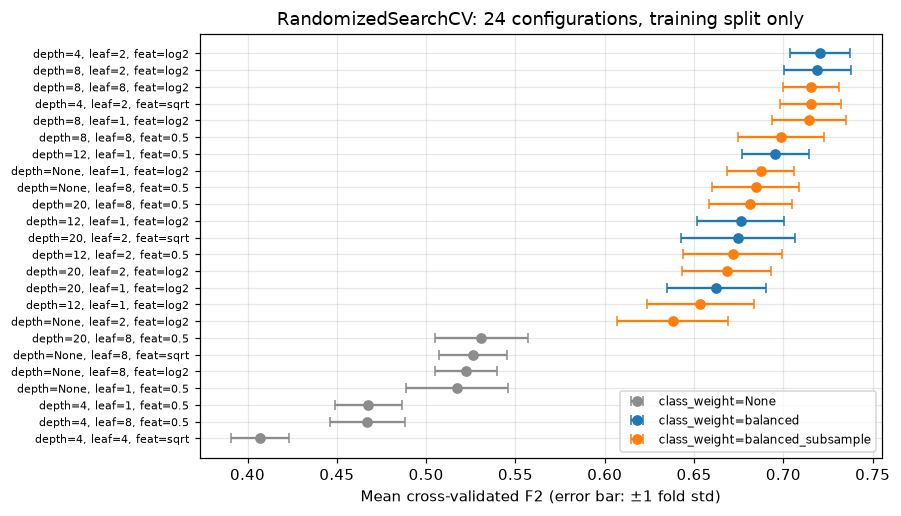

In [9]:
rs = pd.DataFrame(random_search.cv_results_).sort_values('mean_test_score').reset_index(drop=True)
weights = rs['param_model__class_weight'].astype(str)
colours = {'None': '#8c8c8c', 'balanced': '#1f77b4', 'balanced_subsample': '#ff7f0e'}
fig, ax = plt.subplots(figsize=(8, 5))
for name, colour in colours.items():
    part = rs[weights == name]
    ax.errorbar(part['mean_test_score'], part.index, xerr=part['std_test_score'],
                fmt='o', color=colour, capsize=3, label=f'class_weight={name}')
ax.set_yticks(rs.index)
ax.set_yticklabels([
    f"depth={r.param_model__max_depth}, leaf={r.param_model__min_samples_leaf}, feat={r.param_model__max_features}"
    for r in rs.itertuples()
], fontsize=7)
ax.set_xlabel('Mean cross-validated F2 (error bar: ±1 fold std)')
ax.set_title('RandomizedSearchCV: 24 configurations, training split only')
ax.legend(loc='lower right', fontsize=8)
save(fig, '02_random_search')

### Narrow the space

The random-search results define a smaller grid. The rule was fixed *before* looking at any scores, so the narrowing cannot be bent towards a preferred answer:

1. Take the **top 5** random-search configurations as the promising region.
2. **Categorical settings** (`max_features`, `class_weight`): if the best configuration's value appears in at least 3 of the top 5, freeze it. Otherwise keep every value that appears in the top 5.
3. **Ordered settings** (`n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf`): keep the best value plus its immediate neighbours, one step either side.
4. If the grid exceeds **36 combinations**, freeze the widest ordered setting at its best value until it fits.

**What to look for:** `max_features` frozen at `log2` (it appears in 4 of the top 5), only weighted `class_weight` options kept, and depth limited to 4 or 8. That leaves a 24-combination grid.

In [10]:
grid = narrow_search_space(random_search)
grid

{'model__max_features': ['log2'],
 'model__class_weight': ['balanced', 'balanced_subsample'],
 'model__n_estimators': [200, 300],
 'model__max_depth': [4, 8],
 'model__min_samples_split': [10],
 'model__min_samples_leaf': [1, 2, 4]}

### Focused search: `GridSearchCV`

The narrowed grid is searched exhaustively: all 24 combinations × 5 folds = 120 fits, on the training split only, with the same F2 scorer and folds as the random search.

**What to look for:** a best mean F2 slightly above the random search's best (about 0.726 versus 0.721). That is a modest gain, as expected when refining inside an already good region. With `refit=True`, `grid_search.best_estimator_` is now trained on the full training split.

In [11]:
grid_search = GridSearchCV(
    build_pipeline(), grid, scoring=F2_SCORER, cv=CV, n_jobs=-1, refit=True,
)
grid_search.fit(x_train, y_train)
grid_search.best_params_, round(grid_search.best_score_, 4)

C:\Users\vskti\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\joblib\externals\loky\process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


({'model__class_weight': 'balanced',
  'model__max_depth': 8,
  'model__max_features': 'log2',
  'model__min_samples_leaf': 2,
  'model__min_samples_split': 10,
  'model__n_estimators': 300},
 np.float64(0.7256))

## 3. Selecting the final model

The challenge warns against taking the single best mean score at face value. A configuration can top the ranking because it got lucky on one or two folds. This section inspects how much each top candidate's score **varies across folds** before choosing.

### Inspect `cv_results_` for the top candidates

The table shows the 8 best grid candidates by mean F2, with their fold standard deviation and all five individual fold scores (`split0` to `split4`).

**What to look for:** the leading means are packed within about 0.005 of each other. The fold standard deviations (about 0.017 to 0.023) are several times larger than those gaps, so the ranking by mean alone is fragile.

In [12]:
cv = pd.DataFrame(grid_search.cv_results_)
fold_cols = [f'split{i}_test_score' for i in range(grid_search.n_splits_)]
param_cols = ['param_model__max_depth', 'param_model__min_samples_leaf',
              'param_model__n_estimators', 'param_model__class_weight']
top = cv.sort_values('mean_test_score', ascending=False).head(8)
top[param_cols + ['mean_test_score', 'std_test_score'] + fold_cols].round(4)

,param_model__max_depth,param_model__min_samples_leaf,param_model__n_estimators,param_model__class_weight,mean_test_score,std_test_score,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score
9,8,2,300,balanced,0.7256,0.0185,0.7369,0.6968,0.7220,0.7523,0.7200
8,8,2,200,balanced,0.7242,0.0199,0.7304,0.6942,0.7233,0.7557,0.7174
7,8,1,300,balanced,0.7230,0.0179,0.7348,0.6964,0.7275,0.7467,0.7099
6,8,1,200,balanced,0.7210,0.0227,0.7308,0.6801,0.7267,0.7488,0.7187
5,4,4,300,balanced,0.7209,0.0169,0.7212,0.6975,0.7164,0.7503,0.7190
10,8,4,200,balanced,0.7208,0.0188,0.7329,0.6877,0.7237,0.7431,0.7169
3,4,2,300,balanced,0.7205,0.0169,0.7190,0.6975,0.7168,0.7503,0.7190
0,4,1,200,balanced,0.7203,0.0194,0.7190,0.6949,0.7177,0.7550,0.7147


### Mean versus stability across folds

**Left:** every grid candidate, plotted by mean F2 against fold standard deviation. The shaded strip is the **near-tie band**: candidates within 0.01 F2 of the best mean, which is smaller than the fold-to-fold noise. Ideal candidates sit towards the bottom right (high mean, low variation).

**Right:** the five fold scores for the two finalists, the highest-mean model (depth 8) and the most stable model in the band (depth 4).

**How to read it:** the two finalists score almost identically on folds 2, 4 and 5. The depth-8 model's higher average comes mostly from folds 1 and 3. The depth-4 model has the lowest spread in the band.

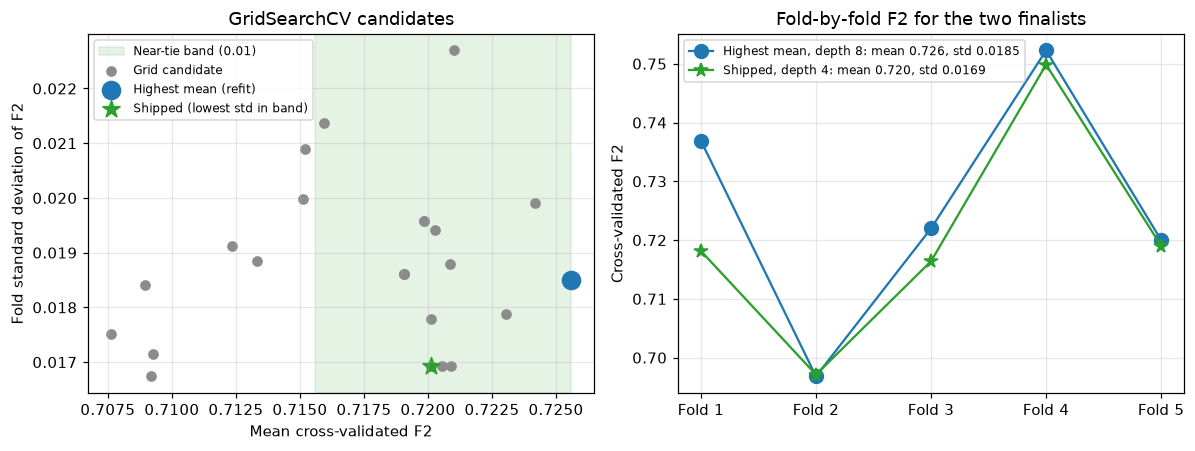

In [13]:
selection_preview = select_from_grid(grid_search)
refit_i, chosen_i = selection_preview['refit_index'], selection_preview['chosen_index']
best_mean = cv['mean_test_score'].max()

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.2))
left.axvspan(best_mean - NEAR_TIE_BAND, best_mean, color='#2ca02c', alpha=0.12, label='Near-tie band (0.01)')
left.scatter(cv['mean_test_score'], cv['std_test_score'], color='#8c8c8c', label='Grid candidate')
left.scatter(*cv.loc[refit_i, ['mean_test_score', 'std_test_score']], s=140, color='#1f77b4', label='Highest mean (refit)')
left.scatter(*cv.loc[chosen_i, ['mean_test_score', 'std_test_score']], s=140, color='#2ca02c', marker='*', label='Shipped (lowest std in band)')
left.set_xlabel('Mean cross-validated F2')
left.set_ylabel('Fold standard deviation of F2')
left.set_title('GridSearchCV candidates')
left.legend(fontsize=8)

folds = [f'Fold {i + 1}' for i in range(len(fold_cols))]
for idx, label, colour, marker in [
    (refit_i, 'Highest mean, depth 8', '#1f77b4', 'o'),
    (chosen_i, 'Shipped, depth 4', '#2ca02c', '*'),
]:
    scores = cv.loc[idx, fold_cols].astype(float).values
    right.plot(folds, scores, marker=marker, markersize=9, color=colour,
               label=f'{label}: mean {scores.mean():.3f}, std {scores.std():.4f}')
right.set_ylabel('Cross-validated F2')
right.set_title('Fold-by-fold F2 for the two finalists')
right.legend(fontsize=8)
fig.tight_layout()
save(fig, '03_grid_stability')

### Choose and justify

The selection rule was fixed in `PLAN.md` before any test score existed:

1. Keep every grid candidate whose mean F2 is within **0.01** of the best mean (the near-tie band).
2. Within the band, choose the candidate with the **lowest fold standard deviation**.
3. If that is the refit winner, use `best_estimator_` as is. Otherwise fit the chosen configuration **once** on the training split. `best_estimator_` is never re-fit manually.

**Result:** the rule picks the **depth-4 forest** over the highest-mean depth-8 forest.

| | Highest mean (refit winner) | **Shipped** |
| --- | --- | --- |
| `max_depth` | 8 | **4** |
| `min_samples_leaf` | 2 | **1** |
| Mean CV F2 | 0.7256 | 0.7201 |
| Fold std | 0.0185 | **0.0169** |

Both use 300 trees, `min_samples_split=10`, `max_features="log2"` and `class_weight="balanced"`.

**Trade-off:** the shipped model gives up 0.0055 mean F2, well inside fold noise, for a lower spread across folds and a simpler model (trees half as deep). A shallower forest is less likely to overfit as customer behaviour drifts, which matters for a model headed to production. The edge is small, and shipping the depth-8 model would also be defensible. The rule was followed as written and not changed after seeing results.

The next cell builds the final model according to the rule.

In [14]:
selection = select_from_grid(grid_search)
{k: selection[k] for k in ['refit_mean_f2', 'refit_std_f2', 'chosen_mean_f2', 'chosen_std_f2', 'chosen_params', 'reason']}

{'refit_mean_f2': 0.725596560791027,
 'refit_std_f2': 0.018501337403927624,
 'chosen_mean_f2': 0.7201102873522978,
 'chosen_std_f2': 0.016924525993630608,
 'chosen_params': {'model__class_weight': 'balanced',
  'model__max_depth': 4,
  'model__max_features': 'log2',
  'model__min_samples_leaf': 1,
  'model__min_samples_split': 10,
  'model__n_estimators': 300},
 'reason': 'A grid candidate within 0.01 mean F2 of the leader has a lower fold standard deviation. That candidate is the shipped model. It is fit once on the training split. best_estimator_ is not fit again.'}

In [15]:
if selection['use_refit_estimator']:
    final_model = grid_search.best_estimator_
else:
    final_model = build_pipeline().set_params(**selection['chosen_params'])
    final_model.fit(x_train, y_train)

### Final tuned model (test-set use 2 of 2)

The selected model predicts on the test set **once**. That one set of predictions produces the six metrics below and every chart that follows, so the test set is not scored again. No search or setting is changed after this point.

**What to look for:** a large jump in F2 and recall over the baseline, a drop in precision and accuracy, and little change in ROC AUC.

In [16]:
tuned_pred = final_model.predict(x_test)
tuned_proba = final_model.predict_proba(x_test)[:, 1]
tuned_test = metrics_from_predictions(y_test, tuned_pred, tuned_proba)
comparison = pd.DataFrame({'baseline': baseline_test, 'tuned': tuned_test})
comparison['change'] = comparison['tuned'] - comparison['baseline']
comparison.round(4)

,baseline,tuned,change
f2,0.5167,0.6993,0.1826
recall,0.4973,0.7834,0.2861
precision,0.6118,0.4891,-0.1227
f1,0.5487,0.6023,0.0536
roc_auc,0.8226,0.8349,0.0123
accuracy,0.7828,0.7253,-0.0575


### Baseline versus tuned, same metrics

Side-by-side test-set scores for both models on the same six metrics.

**How to read it:**
- **F2 (+0.18) and recall (+0.29) rise sharply.** This is the improvement the business asked for.
- **Precision (−0.12) and accuracy (−0.06) fall.** The tuned model flags more customers, so more of its flags are false alarms. That is the accepted cost of catching more churners.
- **ROC AUC barely moves (+0.01).** The model does not rank customers much better. The gain comes from *where* it draws the line between "stays" and "churns", which class weighting shifts towards catching churn.

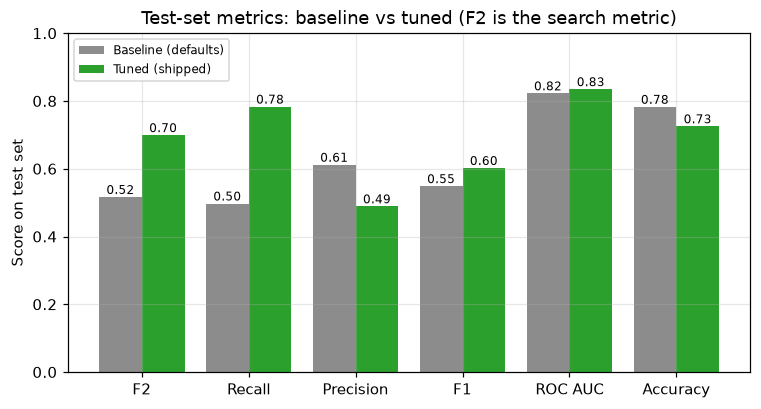

In [17]:
names = ['F2', 'Recall', 'Precision', 'F1', 'ROC AUC', 'Accuracy']
keys = ['f2', 'recall', 'precision', 'f1', 'roc_auc', 'accuracy']
x = np.arange(len(keys))
fig, ax = plt.subplots(figsize=(8, 4))
b1 = ax.bar(x - 0.2, [baseline_test[k] for k in keys], 0.4, color='#8c8c8c', label='Baseline (defaults)')
b2 = ax.bar(x + 0.2, [tuned_test[k] for k in keys], 0.4, color='#2ca02c', label='Tuned (shipped)')
ax.bar_label(b1, fmt='%.2f', fontsize=8)
ax.bar_label(b2, fmt='%.2f', fontsize=8)
ax.set_xticks(x, names)
ax.set_ylim(0, 1)
ax.set_ylabel('Score on test set')
ax.set_title('Test-set metrics: baseline vs tuned (F2 is the search metric)')
ax.legend(loc='upper left', fontsize=8)
save(fig, '04_test_metrics')

### Where the business gain shows up

The confusion matrices count each kind of outcome on the 1,409 test customers (374 of whom churn):

- **Bottom-left cell: churners the model missed.** This is the expensive mistake StreamLoop most wants to avoid.
- **Top-right cell: retention offers sent to customers who would have stayed.** This is the cheaper mistake.

The ROC curve on the right shows ranking quality across all thresholds. The two curves almost overlap, which confirms the gain comes from the operating point rather than a better underlying ranking.

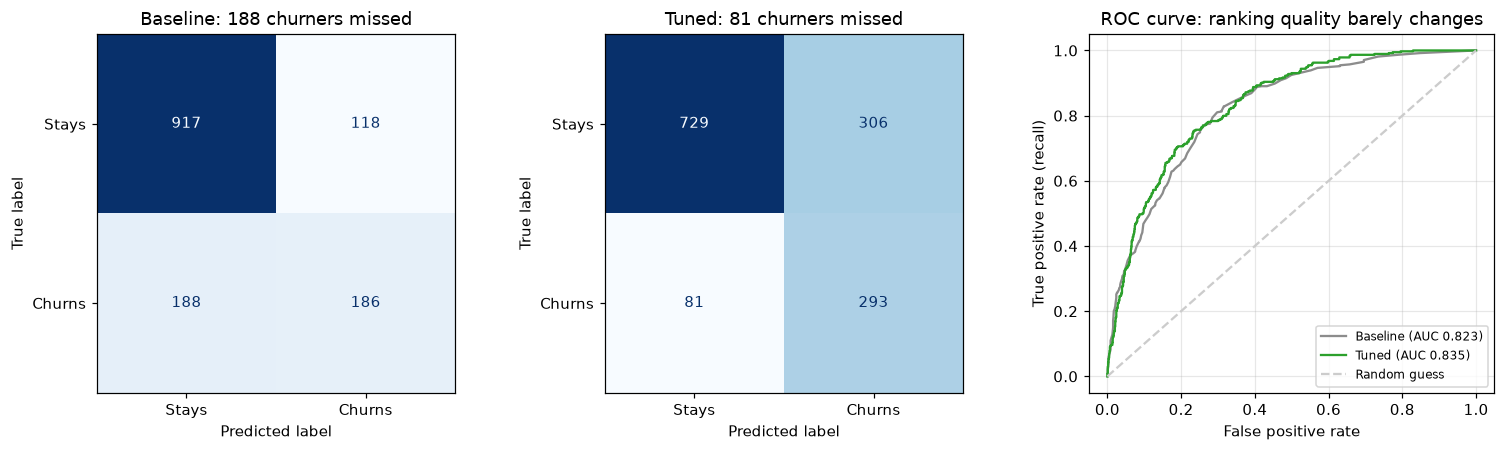

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, pred, title in [(axes[0], baseline_pred, 'Baseline'), (axes[1], tuned_pred, 'Tuned')]:
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=['Stays', 'Churns'], cmap='Blues', colorbar=False, ax=ax)
    missed = int(((y_test == 1) & (pred == 0)).sum())
    ax.set_title(f'{title}: {missed} churners missed')
    ax.grid(False)
for proba, name, colour in [(baseline_proba, 'Baseline', '#8c8c8c'), (tuned_proba, 'Tuned', '#2ca02c')]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[2].plot(fpr, tpr, color=colour, label=f'{name} (AUC {roc_auc_score(y_test, proba):.3f})')
axes[2].plot([0, 1], [0, 1], linestyle='--', color='#cccccc', label='Random guess')
axes[2].set_xlabel('False positive rate')
axes[2].set_ylabel('True positive rate (recall)')
axes[2].set_title('ROC curve: ranking quality barely changes')
axes[2].legend(fontsize=8)
fig.tight_layout()
save(fig, '05_confusion_and_roc')

## 4. Final verdict

**Recommendation: ship the tuned random forest.** It is a clear improvement on the default model for StreamLoop's goal of catching customers before they leave.

### What changed on the test set

| Metric | Baseline | Tuned | Change |
| --- | ---: | ---: | ---: |
| **F2** (business metric) | 0.517 | **0.699** | **+0.183** |
| Recall | 0.497 | 0.783 | +0.286 |
| Precision | 0.612 | 0.489 | −0.123 |
| F1 | 0.549 | 0.602 | +0.054 |
| ROC AUC | 0.823 | 0.835 | +0.012 |
| Accuracy | 0.783 | 0.725 | −0.057 |

- **Churners caught:** the tuned model catches 293 of 374 churners in the test set (78%), up from 186 (50%). Missed churners fall from **188 to 81**, so 107 more at-risk customers can receive a retention offer.
- **Cost:** retention offers to customers who would have stayed rise from 118 to 306. Since a missed churner costs far more than an unneeded offer, this is the trade StreamLoop asked for.
- **Accuracy fell.** That is expected and acceptable: accuracy rewards ignoring churners, so it was deliberately not the target.

### Final hyperparameters

`n_estimators=300`, `max_depth=4`, `min_samples_split=10`, `min_samples_leaf=1`, `max_features="log2"`, `class_weight="balanced"` (with `random_state=42`).

### Why this configuration

- **Searched, not guessed.** 24 random configurations mapped the space, and a 24-combination grid refined the best region. That is 240 cross-validated fits in total.
- **Stable, not just top-ranked.** It scored within 0.01 F2 of the best mean and had the lowest fold-to-fold variation in that group. It is also the simpler of the two finalists.
- **Honest estimate.** Cross-validated F2 was 0.720 and test F2 is 0.699. The gap is within the range seen across folds (0.697 to 0.750), so the test result is consistent with what cross-validation predicted.

### Challenge checklist

| Requirement | Met |
| --- | --- |
| Preprocessing inside a `Pipeline`, split done first | Yes |
| Default baseline trained and recorded before tuning | Yes |
| `RandomizedSearchCV` before `GridSearchCV` | Yes |
| Cross-validation on the training split only; test set used twice | Yes |
| `scoring` set deliberately (F2) with a business reason | Yes |
| `cv_results_` inspected for variation across folds | Yes |
| Final choice justified, trade-off stated | Yes |
| Baseline and tuned compared on the same metrics | Yes |

### Limitations and next steps

- **Decision threshold.** The cutoff is still 0.5. Tuning it against StreamLoop's real costs (the value of a saved customer versus the cost of an offer) is the next and likely largest lever.
- **Stability of the ranking.** The depth-4 versus depth-8 choice is close. Repeating cross-validation with other random seeds would show whether the preference holds.
- **Monitoring.** Customer behaviour drifts over time. Recall should be tracked in production, and the model retuned when it slips.

The full written report is in `tuning_report.md`.